In [4]:
# using python 3.9 environment

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.model_selection import train_test_split

import torch
from torchvision import datasets
from torchvision import transforms
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F


import os
import cv2

import glob 
import cuvis


In [5]:

def loadMeasurement(userSettingsDir, measurementLoc):

    # print("loading user settings...")
    settings = cuvis.General(userSettingsDir)
    # settings.set_log_level("info")

    # print("loading measurement file...")
    mesu = cuvis.Measurement(measurementLoc)
    # print("Data 1 {} t={}ms mode={}".format(mesu.name,mesu.integration_time,mesu.processing_mode.name,))

    # if not isinstance(mesu.MeasurementFlags, list):
    #     mesu.MeasurementFlags = [mesu.MeasurementFlags]

    # if isinstance(mesu.measurement_flags, cuvis.MeasurementFlags):
    #     print(f"Flags: {mesu.measurement_flags}")
    #     for v in cuvis.MeasurementFlags.supremum():
    #         print(f'{v}: {v in mesu.measurement_flags}')
    
    cube = mesu.data.get("cube", None)
    if cube is None:
        raise Exception("Cube not found")
    cube = cube.array
    # print(cube.shape)
    # cube_reshaped = cube.reshape(cube.shape[2], cube.shape[0], cube.shape[1])
    cube_result = np.transpose(cube, (2, 0, 1))
    # print(cube_result.shape)
    cube = cube_result
    if cube is None:
        raise Exception("Cube not found")
    
    # print("Cube shape: ", cube.shape)
    return cube/10000

   
def   reprocessMeasurement(userSettingsDir,measurementLoc,darkLoc,whiteLoc,distanceLoc,factoryDir):    
    
    # print("loading user settings...")
    settings = cuvis.General(userSettingsDir)
    # settings.setLogLevel("info")

    # print("loading measurement file...")
    mesu = cuvis.Measurement(measurementLoc)
    
    
    #  // Get the GPS data
    # const cuvis::Measurement::gps_data_t* gps_data = measurement.get_gps();

    # // Iterate over the GPS data and print the coordinates
    # for (const auto& pair : *gps_data) {
    #     std::cout << "Key: " << pair.first << ", Latitude: " << pair.second.latitude << ", Longitude: " << pair.second.longitude << std::endl;
    # }
    
    # # Get the GPS data
    # gps_data = mesu.get_gps()

    # # Iterate over the GPS data and print the coordinates
    # for key, gps in gps_data.items():
    #     print(f"Key: {key}, Latitude: {gps.latitude}, Longitude: {gps.longitude}")
        

    # print("loading dark...")
    dark = cuvis.Measurement(darkLoc)
    # print("loading white...")
    white = cuvis.Measurement(whiteLoc)
    # print("loading dark...")
    distance = cuvis.Measurement(distanceLoc)

    # print("Data 1 {} t={}ms mode={}".format(mesu.Name,mesu.IntegrationTime,mesu.ProcessingMode,))

    # print("loading calibration and processing context (factory)...")
    calibration = cuvis.Calibration(factoryDir)
    processingContext = cuvis.ProcessingContext(calibration)

    # print("set references...")
    processingContext.set_reference(dark, cuvis.ReferenceType.Dark)
    processingContext.set_reference(white, cuvis.ReferenceType.White)
    processingContext.set_reference(distance, cuvis.ReferenceType.Distance)

    modes = [
             "Reflectance"
             ]

    # procArgs = cuvis.CubertProcessingArgs()
    procArgs = cuvis.ProcessingArgs()
    # saveArgs = cuvis.SaveArgs(allow_overwrite=True)

    for mode in modes:

        procArgs.ProcessingMode = mode
        isCapable = processingContext.is_capable(mesu, procArgs)

        if isCapable:
            # print("processing to mode {}...".format(mode))
            processingContext.set_processing_args(procArgs)
            mesu = processingContext.apply(mesu)
            mesu.set_name(mode)
            # cube = mesu.Data.pop("cube", None)
            cube = mesu.data.get("cube", None)
            
            if cube is None:
                raise Exception("Cube not found")

        else:
            print("Cannot process to {} mode!".format(mode))
            
    #print("finished.")
    cube_result = cube.array
    cube_result = np.transpose(cube_result, (2, 0, 1))
    # print(cube_result.shape)
    return cube_result/4096


class AutoencoderDataset(Dataset):
    def __init__(self,  dataset_name, image_set,  root_dir, transform=None):
        self.dataset_name = dataset_name
        self.image_set = image_set
        self.transform = transform
        self.root = root_dir
        self.img_dir = root_dir
        self.img_names = [f for f in os.listdir(self.img_dir) if f.endswith('.' + 'cu3')]
        print(self.img_names)

        self.num_images = len( self.img_names  )

    def __getitem__(self, index):
        
        hyperspectral_image1 =self.root + self.img_names[index]
        # print(hyperspectral_image1)
        
        if (use_load_measurement):
            hyperImage = loadMeasurement(userSettingsDir,hyperspectral_image1)
        elif (use_reprocess_measurement):
            hyperImage = reprocessMeasurement(userSettingsDir,hyperspectral_image1,darkLoc,whiteLoc,distanceLoc,factoryDir)
        # hyperImage = loadMeasurement(userSettingsDir,hyperspectral_image1)
        # hyperImage = reprocessMeasurement(userSettingsDir,hyperspectral_image1,darkLoc,whiteLoc,distanceLoc,factoryDir)
        data = hyperImage.astype(np.float32)
        # print(data)
        # print max value in data
        print(np.max(data))
        
        # print(data.shape)
        # Assuming `data` is your numpy array with shape (51, 275, 290)
        data = np.expand_dims(data, axis=0)  # Add a new dimension, resulting in shape (1, 51, 275, 290)
        # print(data.shape)
        # Convert numpy array to PyTorch tensor
        data = torch.from_numpy(data)
        
        # Assuming `data` is your tensor with shape (51, 275, 290)
        # data = data.unsqueeze(0)  # Add batch dimension, resulting in shape (1, 51, 275, 290)
        # print(data.shape)
        # Resize data
        resized_data = F.interpolate(data, size=(273, 273), mode='bilinear', align_corners=False)

        resized_data = resized_data.squeeze(0)  # Remove batch dimension, resulting in shape (51, 275, 275)
        # print(resized_data.shape)
        # print(resized_data)
        return resized_data

    def __len__(self):
        return self.num_images
    
        
# Creating a PyTorch class
# 28*28 ==> 9 ==> 28*28
class spectral_AE_threeD(torch.nn.Module):
    def __init__(self):
        super().__init__()

        # Building an linear encoder with Linear
        # layer followed by Relu activation function
        # 140 ==> 3
        self.encoder = torch.nn.Sequential(
            torch.nn.Linear(num_data_points, 64),
            torch.nn.ReLU(),
            torch.nn.Linear(64, 32),
            torch.nn.ReLU(),
            torch.nn.Linear(32, 16),
            torch.nn.ReLU(),
            torch.nn.Linear(16, 8),
            torch.nn.ReLU(),
            torch.nn.Linear(8, 3),
        )

        # Building an linear decoder with Linear
        # layer followed by Relu activation function
        # The Sigmoid activation function
        # outputs the value between 0 and 1
        # 3 ==> 140
        self.decoder = torch.nn.Sequential(
            torch.nn.Linear(3, 8),
            torch.nn.ReLU(),
            torch.nn.Linear(8, 16),
            torch.nn.ReLU(),
            torch.nn.Linear(16, 32),
            torch.nn.ReLU(),
            torch.nn.Linear(32, 64),
            torch.nn.ReLU(),
            torch.nn.Linear(64, num_data_points),
            torch.nn.Sigmoid()
        )

    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return encoded, decoded    


class ConvAutoencoder(torch.nn.Module):
    def __init__(self):
        super(ConvAutoencoder, self).__init__()
        
        # Encoder
        self.encoder =  torch.nn.Sequential(
            # torch.nn.Conv2d(275, 128, kernel_size=3, stride=2, padding=1),
            # torch.nn.ReLU(),
            # torch.nn.Conv2d(128, 64, kernel_size=3, stride=2, padding=1),
            # torch.nn.ReLU(),
            torch.nn.Conv2d(num_channels, 32, kernel_size=3, stride=2, padding=1),
            torch.nn.ReLU(),
            torch.nn.Conv2d(32, 16, kernel_size=3, stride=2, padding=1),
            torch.nn.ReLU(),
            torch.nn.Conv2d(16, 3, kernel_size=3, stride=2, padding=1),
            # torch.nn.ReLU(),
        )
        
        # Decoder
        self.decoder =  torch.nn.Sequential(
            # torch.nn.ConvTranspose2d(3, 16, kernel_size=3, stride=2, padding=1, output_padding=0),
            # torch.nn.ReLU(),
            # torch.nn.ConvTranspose2d(16, 32, kernel_size=3, stride=2, padding=1, output_padding=0),
            # torch.nn.ReLU(),
            # torch.nn.ConvTranspose2d(32, 51, kernel_size=3, stride=2, padding=2, output_padding=1),
            # # torch.nn.ReLU(),
            # # torch.nn.ConvTranspose2d(64, 128, kernel_size=3, stride=2, padding=1, output_padding=1),
            # # torch.nn.ReLU(),
            # # torch.nn.ConvTranspose2d(128, 275, kernel_size=3, stride=2, padding=1, output_padding=1),
            # torch.nn.Sigmoid(),
            torch.nn.ConvTranspose2d(3, 16, kernel_size=3, stride=2, padding=1, output_padding=0),  # Adjust output_padding
            torch.nn.ReLU(),
            torch.nn.ConvTranspose2d(16, 32, kernel_size=3, stride=2, padding=1, output_padding=0),  # Adjust output_padding
            torch.nn.ReLU(),
            torch.nn.ConvTranspose2d(32, num_channels, kernel_size=3, stride=2, padding=1, output_padding=0),  # Adjust output_padding
            torch.nn.Sigmoid(),
        )

    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return  encoded, decoded 
    
    
def extract_rgb(cube, red_layer=78 , green_layer=40, blue_layer=25,  visualize=False):

  
    red_img = cube[ red_layer,:,:]
    green_img = cube[ green_layer,:,:]
    blue_img = cube[ blue_layer,:,:]

        
    data=np.stack([red_img,green_img,blue_img], axis=-1)
    # print(data.shape)
    #print(type(image))

    #convert to 8bit
    x_norm = (data-np.min(data))/(np.max(data)-np.min(data))
    image=(x_norm*255).astype('uint8')
    if visualize:
        #pass
        plt.imshow(image)
        plt.show()
    return image 

In [6]:
input_data_dir = "/workspaces/HyperImages/cornfields/session_002/" # need to reprocess this data
userSettingsDir = "/workspaces/HyperTools/settings/ultris20/" 
darkLoc = "../../HyperImages/cornfields/Calibration/dark__session_002_003_snapshot16423119279414228.cu3"
whiteLoc = "../../HyperImages/cornfields/Calibration/white__session_002_752_snapshot16423136896447489.cu3"
distanceLoc = "../../HyperImages/cornfields/Calibration/distanceCalib__session_000_790_snapshot16423004058237746.cu3"
factoryDir = "../settings/ultris20/" # init.daq file
outDir ="../../HyperImages/export/"
dataset='cornfields'
use_reprocess_measurement=True
use_load_measurement=False
num_channels = 164


# input_data_dir = "/workspaces/HyperImages/cornflakes_and_pasta/cornflakes_and_noodles_000/"
# userSettingsDir = "/workspaces/HyperTools/settings/ultris20/" 
# dataset='cornflakes_and_pasta'
# use_load_measurement=True
# num_channels = 51

full_dataset = AutoencoderDataset(dataset_name=dataset, root_dir=input_data_dir, image_set='train')

spectral_train_data, spectral_test_data = train_test_split(
    full_dataset,  test_size=0.3, random_state=21
)
train_loader = DataLoader(spectral_train_data, batch_size=2, shuffle=True,num_workers=4)
test_loader = DataLoader(spectral_test_data, batch_size=1,num_workers=4)

print(len(spectral_test_data), len(spectral_train_data), full_dataset.num_images)

['session_002_499.cu3', 'session_002_500.cu3', 'session_002_504.cu3', 'session_002_495.cu3', 'session_002_502.cu3', 'session_002_490.cu3', 'session_002_509.cu3', 'session_002_501.cu3', 'session_002_498.cu3', 'session_002_505.cu3', 'session_002_503.cu3', 'session_002_508.cu3', 'session_002_496.cu3', 'session_002_507.cu3', 'session_002_506.cu3', 'session_002_492.cu3', 'session_002_497.cu3', 'session_002_494.cu3', 'session_002_493.cu3', 'session_002_491.cu3']
0.20874023
0.26245117
0.28222656
0.2253418
0.34423828
0.24145508
0.21850586
0.2121582
0.21411133
0.2512207
0.2241211
0.34326172
0.22094727
0.20019531
0.38891602
0.24609375
0.22045898
0.23022461
0.234375
0.20800781
6 14 20


0.2121582
torch.Size([164, 273, 273])


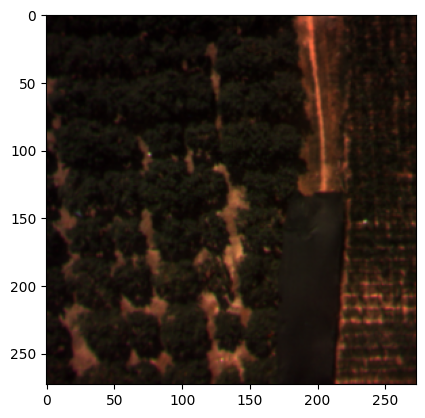

In [7]:
example= full_dataset[3]

print(example.shape)

if num_channels == 51:
    example1_image = extract_rgb(example, 31,13,2)
else:
    example1_image = extract_rgb(example)

plt.imshow(example1_image)
plt.show()

num_data_points = example.shape[0] * example.shape[1] * example.shape[2]

In [11]:
spectral_model = ConvAutoencoder()


loss_function = torch.nn.L1Loss()
criterion = torch.nn.MSELoss()
device  = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# print (device)
spectral_model = spectral_model.to(device)
optimizer = torch.optim.Adam(spectral_model.parameters(),
                             lr = 1e-3,
                             weight_decay = 1e-4)

epochs = 5
history_loss_train = []
history_loss_val = []
for epoch in range(epochs):
    spectral_model.train()
    for inputs in train_loader:
        # print(inputs.shape)
        # inputs = inputs.view(inputs.size(0), -1)  # Flatten the inputs

        inputs = inputs.float().to(device)
        encoded, outputs = spectral_model(inputs)
        # print(inputs.shape, outputs.shape)
        loss = criterion(outputs, inputs)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    spectral_model.eval()
    with torch.no_grad():
        for inputs in test_loader:
            # inputs = inputs.view(inputs.size(0), -1)  # Flatten the inputs

            inputs = inputs.float().to(device)
            encoded, outputs = spectral_model(inputs)
            val_loss = criterion(outputs, inputs)
    history_loss_train.append(loss.item())
    history_loss_val.append(val_loss.item())
    print(f'Epoch {epoch+1}/{epochs}, Loss: {loss.item()}, Validation Loss: {val_loss.item()}')

Epoch 1/5, Loss: 0.22505587339401245, Validation Loss: 0.2252938151359558
Epoch 2/5, Loss: 0.21750156581401825, Validation Loss: 0.2190941870212555
Epoch 3/5, Loss: 0.20576509833335876, Validation Loss: 0.21007083356380463
Epoch 4/5, Loss: 0.18890872597694397, Validation Loss: 0.19256901741027832
Epoch 5/5, Loss: 0.13623812794685364, Validation Loss: 0.12210052460432053


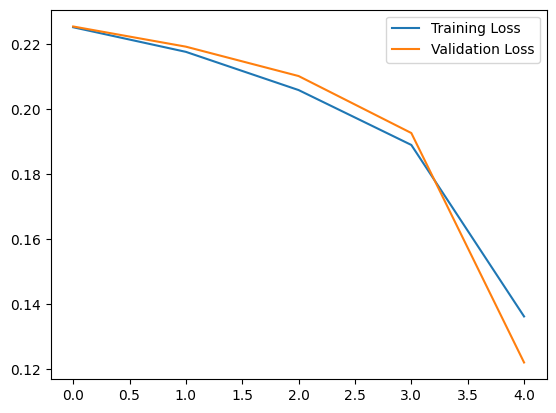

In [12]:
plt.plot(history_loss_train, label="Training Loss")
plt.plot(history_loss_val, label="Validation Loss")
plt.legend()


(164, 273, 273) (164, 273, 273) torch.Size([3, 35, 35])
(35, 35, 3)


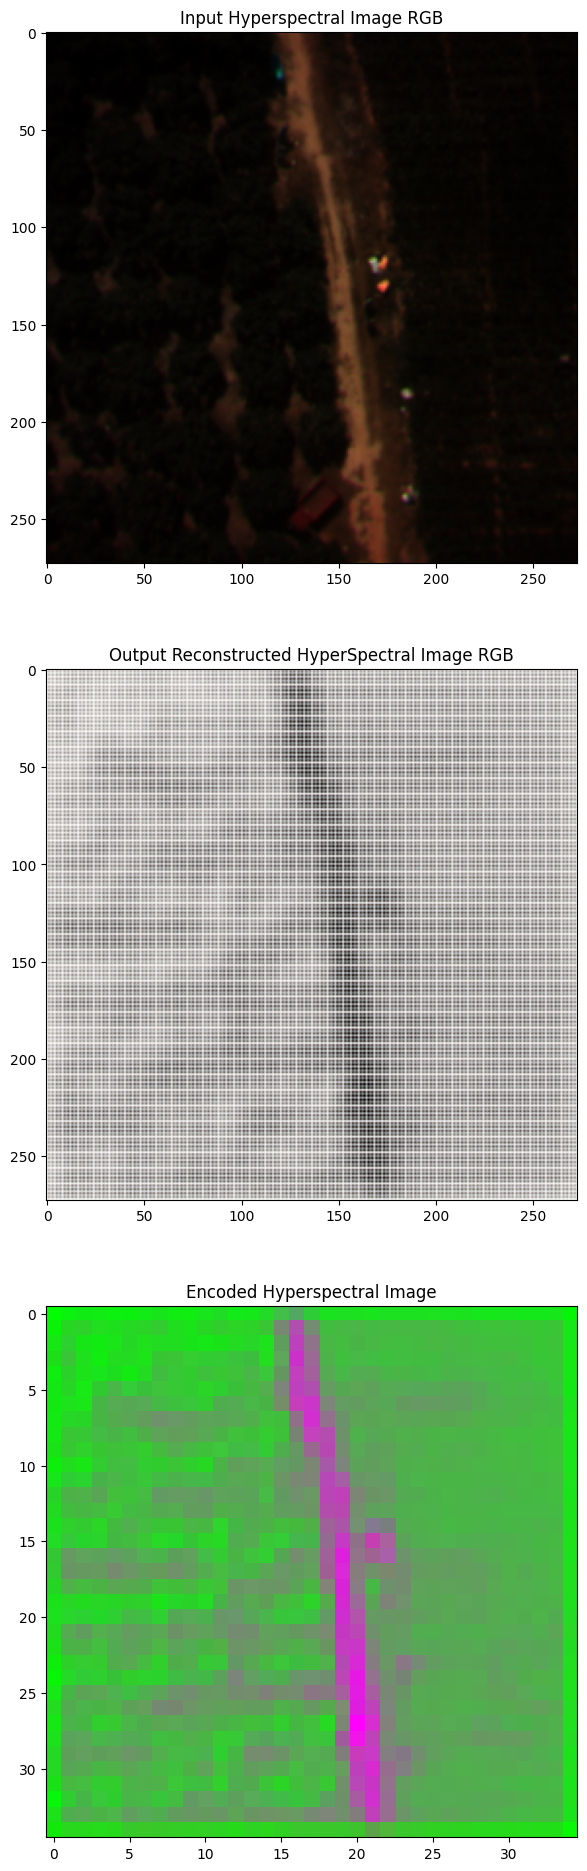

In [15]:
import matplotlib.pyplot as plt





# # Get a batch of test data
# test_data_iter = iter(test_loader)
# inputs = next(test_data_iter)
# Get the first batch of test data
first_batch = next(iter(test_loader))

# Select the first item from the batch
first_item = first_batch[0]
# Move the inputs to the device
first_item = first_item.float().to(device)

# Get the model's reconstruction of the inputs
encoded, outputs = spectral_model(first_item)

# Move the inputs and outputs to the CPU for plotting
first_item = first_item.cpu()
outputs = outputs.cpu()

# Detach the inputs and outputs from the computation graph
first_item = first_item.detach().numpy()
outputs = outputs.detach().numpy()

print(first_item.shape, outputs.shape, encoded.shape)

# Transpose the dimensions of the encoded representation
encoded_transposed = np.transpose(encoded.cpu().detach().numpy(), (1, 2, 0))
print(encoded_transposed.shape)




if num_channels == 51:
    example_image = extract_rgb(first_item, 31,13,2)
    example_image2 = extract_rgb(outputs, 31,13,2)
else:
    example_image = extract_rgb(first_item)
    example_image2 = extract_rgb(outputs)
    
    

# Initialize an empty array for the normalized data
normalized = np.empty_like(encoded_transposed)

# Iterate over each channel
for i in range(encoded_transposed.shape[2]):
    # Get the current channel
    channel = encoded_transposed[:, :, i]

    # Normalize the current channel
    normalized_channel = (channel - channel.min()) / (channel.max() - channel.min())

    # Store the normalized channel
    normalized[:, :, i] = normalized_channel
    
    
    

fig = plt.figure(figsize=(20, 40))

plt.subplot(5, 1, 1)  # 1 row, 3 columns, 1st subplot = image1
plt.imshow(example_image)
plt.title('Input Hyperspectral Image RGB')

plt.subplot(5, 1, 2)  # 1 row, 3 columns, 1st subplot = image1
plt.imshow(example_image2)
plt.title('Output Reconstructed HyperSpectral Image RGB')


plt.subplot(5, 1, 3)  # 1 row, 3 columns, 1st subplot = image1
plt.imshow(normalized)
plt.title('Encoded Hyperspectral Image')


plt.show()
